## ANN Parameter Tuning (California Housing Dataset)

#### Dataset Information and Column Descriptions

This notebook uses the **California Housing dataset**, derived from the 1990 California census. Each row represents a California housing district (block group). The goal is to predict the district's median house value from demographic and geographic features.

- **Samples:** 20,640 housing districts
- **Raw columns:** 9
- **Target:** `median_house_value` - median house value for the district

The columns below follow the exact order in the raw data file:

| Column | Description |
| --- | --- |
| `longitude` | Geographic longitude of the district. |
| `latitude` | Geographic latitude of the district. |
| `housing_median_age` | Median age of houses in the district, in years. |
| `total_rooms` | Total number of rooms across all households in the district. |
| `total_bedrooms` | Total number of bedrooms across all households in the district. |
| `population` | Total number of people living in the district. |
| `households` | Total number of households in the district. |
| `median_income` | Median household income in the district, measured in tens of thousands of US dollars ($10,000). |
| `median_house_value` | Median house value for the district; this is the prediction target. |

In [1]:
# pylint: W0611:unused-import, W0612:unused-variable, W0613:unused-argument, C0114:missing-module-docstring, C0115:missing-class-docstring, C0116:missing-function-docstring

Importing the Libraries

In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
import keras_tuner as kt
import matplotlib.pyplot as plt

Loading the datasets

In [3]:
dataset_path = "./datasets/cal_housing.data"
housing_data = np.loadtxt(dataset_path, delimiter=",")
print('Loaded local dataset from datasets/cal_housing.data')

Loaded local dataset from datasets/cal_housing.data


In [4]:
columns = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income", "median_house_value"]
df = pd.DataFrame(housing_data, columns=columns, index=None)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0


Data Cleaning

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20640.0,537.898014,421.247906,1.0000,295.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20640 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [7]:
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.shape

(20640, 9)

In [11]:
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

In [14]:
print("X Shape: ",X.shape)
print("y Shape: ",y.shape)

X Shape:  (20640, 8)
y Shape:  (20640,)


In [20]:
# train and test split
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, random_state=42, test_size=0.2)
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full, random_state=42, test_size=0.25)

In [21]:
print("X_train Shape: ",X_train.shape, "Percentage of training data: ", (X_train.shape[0]/X.shape[0])*100)
print("y_train Shape: ",y_train.shape, "Percentage of training data: ", (y_train.shape[0]/y.shape[0])*100)
print("X_test Shape: ",X_test.shape, "Percentage of test data: ", (X_test.shape[0]/X.shape[0])*100)
print("y_test Shape: ",y_test.shape, "Percentage of test data: ", (y_test.shape[0]/y.shape[0])*100)
print("X_valid Shape: ",X_valid.shape, "Percentage of validation data: ", (X_valid.shape[0]/X.shape[0])*100)
print("y_valid Shape: ",y_valid.shape, "Percentage of validation data: ", (y_valid.shape[0]/y.shape[0])*100)

X_train Shape:  (12384, 8) Percentage of training data:  60.0
y_train Shape:  (12384,) Percentage of training data:  60.0
X_test Shape:  (4128, 8) Percentage of test data:  20.0
y_test Shape:  (4128,) Percentage of test data:  20.0
X_valid Shape:  (4128, 8) Percentage of validation data:  20.0
y_valid Shape:  (4128,) Percentage of validation data:  20.0


In [22]:
# scaling the dataset

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
X_test = scaler.transform(X_test)
X_train_full = scaler.fit_transform(X_train_full)

In [24]:
## build a parameter tuner
## we are tuning the number of layers, number of nodes in hidden layers and the learning rate

def build_model(hp):
    model = keras.models.Sequential()

    # Tune number of hidden layers: 1 to 4
    num_layers = hp.Int('num_layers', 1, 4)

    # Tune number of nodes in hidden layers: 8 to 64 by increment of 4
    for i in range(num_layers):
        units = hp.Int(f'units_{i}', min_value=8, max_value=64, step=4)
        activation = hp.Choice(f'activation_{i}', ['relu', 'tanh'])

        if i == 0:
            model.add(keras.layers.Dense(units=units, activation=activation, input_shape=X_train.shape[1:]))
        else:
            model.add(keras.layers.Dense(units=units, activation=activation))

    model.add(keras.layers.Dense(1))

    model.compile(
        loss='mse',
        optimizer=keras.optimizers.Adam(learning_rate=hp.Float('lr', 1e-5, 1e-2, sampling='log')),
        metrics=[keras.metrics.RootMeanSquaredError()]
    )

    return model

In [25]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_loss',
    max_trials=20,
    overwrite=True
)

/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [26]:
## run tuner
tuner.search(X_train, y_train,
             validation_data=(X_valid, y_valid),
             epochs=20,
             callbacks=[keras.callbacks.EarlyStopping(patience=3)])

Trial 20 Complete [00h 00m 04s]
val_loss: 57140076544.0

Best val_loss So Far: 4439599616.0
Total elapsed time: 00h 01m 24s


In [27]:
# retreive the best model after tuning
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("\nBest Hyperparameters found:")
print(f"Number of hidden layers: {best_hp.get('num_layers')}")
for i in range(best_hp.get('num_layers')):
    print(f" Layer {i+1}: units = {best_hp.get(f'units_{i}')}, activation = {best_hp.get(f'activation_{i}')}")
print(f"Learning rate: {best_hp.get('lr')}")


Best Hyperparameters found:
Number of hidden layers: 2
 Layer 1: units = 32, activation = relu
 Layer 2: units = 56, activation = relu
Learning rate: 0.009937327304817844


In [28]:
# Get the top 3 hyperparameter sets
best_hps_list = tuner.get_best_hyperparameters(num_trials=3)

print("\n=== Top 3 Hyperparameter Configurations ===\n")
for rank, hp in enumerate(best_hps_list, start=1):
    print(f"Rank #{rank}:")
    for param, value in hp.values.items():
        print(f"  {param}: {value}")
    # Build model with this configuration and evaluate
    model = tuner.hypermodel.build(hp)
    eval_result = model.evaluate(X_test, y_test, verbose=0)
    print(f"  Test RMSE: {eval_result[1]:.4f}\n")


=== Top 3 Hyperparameter Configurations ===

Rank #1:
  num_layers: 2
  units_0: 32
  activation_0: relu
  lr: 0.009937327304817844
  units_1: 56
  activation_1: relu
  units_2: 36
  activation_2: relu
  units_3: 16
  activation_3: relu
  Test RMSE: 235232.6562

Rank #2:
  num_layers: 3
  units_0: 40
  activation_0: relu
  lr: 0.0006356834118028936
  units_1: 8
  activation_1: relu
  units_2: 8
  activation_2: relu


/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Test RMSE: 235232.5312

Rank #3:
  num_layers: 2
  units_0: 64
  activation_0: tanh
  lr: 0.0010298979399685007
  units_1: 24
  activation_1: relu
  units_2: 12
  activation_2: tanh
  units_3: 44
  activation_3: tanh
  Test RMSE: 235232.9688



/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [29]:
# retrain using the best model
print("\nRetraining best model with more epochs...")
best_model = build_model(best_hp)
history = best_model.fit(
    X_train_full, y_train_full,
    validation_data=(X_valid, y_valid),
    epochs=50,
    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
)


Retraining best model with more epochs...
Epoch 1/50


/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 477us/step - loss: 26834399232.0000 - root_mean_squared_error: 163812.0781 - val_loss: 8773564416.0000 - val_root_mean_squared_error: 93667.3047
Epoch 2/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 379us/step - loss: 6678272000.0000 - root_mean_squared_error: 81720.6953 - val_loss: 5472119808.0000 - val_root_mean_squared_error: 73973.7812
Epoch 3/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 374us/step - loss: 4923223552.0000 - root_mean_squared_error: 70165.6875 - val_loss: 4721876992.0000 - val_root_mean_squared_error: 68715.9141
Epoch 4/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 367us/step - loss: 4558155264.0000 - root_mean_squared_error: 67514.1094 - val_loss: 4590691328.0000 - val_root_mean_squared_error: 67754.6406
Epoch 5/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 371us/step - loss: 4464391680.0000 - root_mean_squared_error: 66816.1016 - val_loss: 4551331840.0000 - val_root_mean_squared_error: 67463.5625
Epoch 6/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 365us/step - loss: 4417774592.0000 -

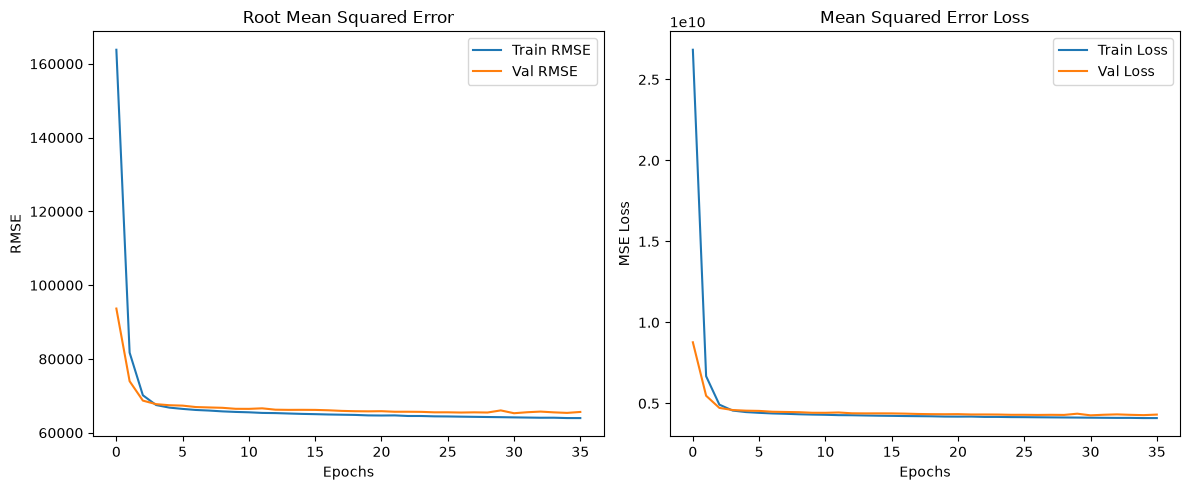

In [30]:
plt.figure(figsize=(12,5))

plt.subplot(1, 2, 1)
plt.plot(history.history['root_mean_squared_error'], label='Train RMSE')
plt.plot(history.history['val_root_mean_squared_error'], label='Val RMSE')
plt.xlabel('Epochs')
plt.ylabel('RMSE')
plt.title('Root Mean Squared Error')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Mean Squared Error Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [31]:
# Final evaluation
loss, rmse = best_model.evaluate(X_test, y_test)
print("\nFinal best model test RMSE:", rmse)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 814us/step - loss: 4201482240.0000 - root_mean_squared_error: 64818.8398

Final best model test RMSE: 64818.83984375
